# Experimento A/B: ¿qué versión de la landing page funciona mejor?

## Resumen

Analicé los resultados de **40,000 usuarios** que vieron una de dos versiones de una landing page durante enero de 2026. Quería saber si la versión B conseguía más conversiones y si eso también se reflejaba en el ingreso.

La versión B tuvo una conversión del **15.96 %**, frente al **12.57 %** de A. Entre quienes compraron, el gasto medio también fue mayor: **68.75** frente a **61.09**. Ambas diferencias fueron estadísticamente significativas.

Con los datos originales calculé además el **ingreso por usuario expuesto**, incluyendo a quienes no compraron: **7.68** para A y **10.97** para B. La diferencia fue de **3.29** unidades monetarias por usuario (IC del 95 %: **2.79 a 3.79**).

**Conclusión:** B es la opción más prometedora en este experimento. Antes de lanzarla para todos, revisaría que la asignación de usuarios haya sido aleatoria y que no haya efectos negativos en otras métricas del negocio.

*El archivo no indica la moneda, así que los importes se expresan en unidades monetarias. El análisis usa un dataset de práctica de TripleTen.*

---


## 1. Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [1]:
# importar librerías

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from scipy.stats import chi2_contingency, ttest_ind
from statsmodels.stats.proportion import proportions_ztest


In [2]:
# Buscar el CSV junto al notebook o dentro de la carpeta data/.
from pathlib import Path
opciones = [Path('data/landing_experiment.csv'), Path('landing_experiment.csv'), Path('/datasets/landing_experiment.csv')]
ruta = next((archivo for archivo in opciones if archivo.exists()), None)
if ruta is None:
    raise FileNotFoundError('Coloca landing_experiment.csv junto al notebook o en data/.')
df = pd.read_csv(ruta)


**Vista previa e información general del conjunto de datos**

In [3]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [4]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB



**Descripción inicial del conjunto de datos**

El dataset contiene 40,000 registros y 9 columnas. No se observan valores ausentes, ya que todas las columnas cuentan con 40,000 valores no nulos.

Las variables categóricas están almacenadas como tipo object, converted como int64 y gasto como float64, tipos adecuados para su contenido.

La única variable que requiere ajuste es date, ya que actualmente es de tipo object y debería convertirse a datetime al representar la fecha de exposición al experimento.

En esta primera revisión, no se identifican otros problemas estructurales evidentes.

**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.


 **Variable `user_id`**  
 Verificar usuarios únicos

In [5]:
# Verificar usuarios únicos
print("Número de registros:", len(df))
print("Usuarios únicos:", df["user_id"].nunique())

Número de registros: 40000
Usuarios únicos: 40000


 **Variable `date`**  
Explorar rango de fechas

In [6]:
# Convertir la columna date a formato datetime
df["date"] = pd.to_datetime(df["date"])


In [7]:
# Resumen estadístico
df["date"].describe()

count                  40000
mean     2026-01-14 11:41:06
min      2026-01-01 00:00:00
25%      2026-01-07 00:00:00
50%      2026-01-14 00:00:00
75%      2026-01-21 00:00:00
max      2026-01-28 00:00:00
Name: date, dtype: object

In [8]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


**Variable `gasto` (numérica)**

In [9]:
# Resumen estadístico de gasto
df["gasto"].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [10]:
# Resumen estadístico de usuarios que se convirtieron
df.loc[df["converted"] == 1, "gasto"].describe()

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [11]:

# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")
print("\nLanding:")
print(df["landing"].value_counts())

print("\nRegión:")
print(df["region"].value_counts())

print("\nDispositivo:")
print(df["dispositivo"].value_counts())

print("\nFuente de tráfico:")
print(df["traffic_source"].value_counts())

print("\nTipo de usuario:")
print(df["user_type"].value_counts())


Conteo de categorías:

Landing:
landing
B    20018
A    19982
Name: count, dtype: int64

Región:
region
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: count, dtype: int64

Dispositivo:
dispositivo
Mobile     24829
Desktop    15171
Name: count, dtype: int64

Fuente de tráfico:
traffic_source
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: count, dtype: int64

Tipo de usuario:
user_type
Nuevo         26033
Recurrente    13967
Name: count, dtype: int64




**Hallazgos de la revisión de calidad de datos**

El dataset contiene 40,000 registros correspondientes a 40,000 usuarios únicos, por lo que no se identifican usuarios duplicados.

La variable date fue convertida a formato de fecha. El experimento se desarrolló entre el 1 y el 28 de enero de 2026, cubriendo 28 días.

La variable gasto no presenta valores negativos. En el conjunto completo predominan los valores de 0, lo cual es consistente con el diseño del dataset, ya que los usuarios que no convierten no generan gasto.

Entre los 5,706 usuarios que sí convirtieron, el gasto promedio es de aproximadamente 65.37, con una mediana de 59.86. El gasto mínimo es 12.12 y el máximo 303.68. La diferencia entre el tercer cuartil (80.37) y el valor máximo sugiere una posible cola hacia valores altos, por lo que será conveniente revisar la distribución del gasto antes de seleccionar e interpretar la prueba estadística.

La variable landing contiene únicamente las categorías esperadas A y B. Los grupos se encuentran prácticamente balanceados: 19,982 usuarios en A y 20,018 en B, una condición favorable para la comparación del experimento.

Las variables categóricas region, dispositivo, traffic_source y user_type presentan categorías consistentes con la descripción del dataset y no se observan errores de escritura ni categorías inesperadas.

Aunque algunas categorías tienen mayor representación que otras —por ejemplo, Mobile, Organic y usuarios Nuevo—, esto describe la composición de la población analizada y no constituye por sí mismo un problema de calidad de datos.



## 2. Comparar el gasto promedio por usuario (página A vs B)

Se evalúa si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [12]:

# Gasto por versión entre usuarios convertidos
gasto_A = df[(df["landing"] == "A") & (df["converted"] == 1)]["gasto"]
gasto_B = df[(df["landing"] == "B") & (df["converted"] == 1)]["gasto"]

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

### Prueba t: gasto entre usuarios convertidos

Comparé el gasto medio de quienes realizaron una compra en A y B. La hipótesis nula es que ambos promedios son iguales; la alternativa es que son distintos. Utilicé una prueba bilateral de Welch, que no exige varianzas iguales, con un nivel de significancia de 0.05.


In [13]:

# Aplicar prueba t de Welch para muestras independientes
estadistico, p_value = ttest_ind(
    gasto_A,
    gasto_B,
    equal_var=False
)

# Visualizar resultados
print(f"Estadístico t: {estadistico:.3f}")
print(f"Valor p: {p_value:.5f}")

Estadístico t: -9.481
Valor p: 0.00000


In [14]:
print(f"Gasto promedio A: {gasto_A.mean():.2f}")
print(f"Gasto promedio B: {gasto_B.mean():.2f}")

Gasto promedio A: 61.09
Gasto promedio B: 68.75


###  Conclusión e interpretación

**Decisión:**
Dado que el valor p es menor que 0.05, se rechaza la hipótesis nula (H₀). Existe evidencia estadísticamente significativa de una diferencia en el gasto promedio de los usuarios convertidos entre la página A y la página B.

**Interpretación de negocio:**
Los usuarios convertidos en la página A registraron un gasto promedio de 61.09, mientras que en la página B el promedio fue de 68.75.

La diferencia observada es de 7.66 unidades monetarias, aproximadamente 12.5% mayor en B respecto a A.

Estos resultados indican que, dentro de este experimento, los usuarios convertidos expuestos a la página B presentaron un gasto promedio mayor que los expuestos a la página A. Sin embargo, este resultado por sí solo no permite explicar qué factores originan la diferencia, por lo que debe interpretarse junto con la tasa de conversión y los análisis por segmento antes de formular una recomendación final.

---

## 3. Conversión: comparación entre A y B

La tasa de conversión permite comparar los resultados teniendo en cuenta el tamaño de cada grupo. Para comprobar si la diferencia observada es estadísticamente significativa utilicé una prueba Z de dos proporciones.


### Prueba z de dos proporciones

**Hipótesis:**

- **Hipótesis nula (H₀):** la tasa de conversión es igual en la página A y en la página B.
- **Hipótesis alternativa (H₁):** la tasa de conversión es diferente entre la página A y la página B.

Se utilizará un nivel de significancia de α = 0.05. Como buscamos determinar si existe una diferencia entre ambas versiones, la prueba será bilateral.


In [15]:

# Número de usuarios convertidos por página
conversiones = df.groupby("landing")["converted"].sum()

# Total de usuarios por página
totales = df.groupby("landing")["converted"].count()

print("Usuarios convertidos por página:\n", conversiones)
print("\nTotal de usuarios por página:\n", totales)



Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: converted, dtype: int64


In [16]:

# Aplicar prueba z de dos proporciones
estadistico, p_value = proportions_ztest(
    count=[conversiones["A"], conversiones["B"]],
    nobs=[totales["A"], totales["B"]]
)

# Visualizar resultados
print(f"Estadístico z: {estadistico:.3f}")
print(f"Valor p: {p_value:.5f}")

Estadístico z: -9.677
Valor p: 0.00000


In [17]:
tasa_A = conversiones["A"] / totales["A"]
tasa_B = conversiones["B"] / totales["B"]

print(f"Tasa de conversión A: {tasa_A:.2%}")
print(f"Tasa de conversión B: {tasa_B:.2%}")

Tasa de conversión A: 12.57%
Tasa de conversión B: 15.96%


###  Conclusión e interpretación

**Decisión:**
Dado que el valor p es menor que 0.05, se rechaza la hipótesis nula (H₀). Existe evidencia estadísticamente significativa de que la tasa de conversión difiere entre la página A y la página B.

**Interpretación de negocio:**

La página A presentó una tasa de conversión de 12.57%, mientras que la página B alcanzó 15.96%.

La diferencia observada es de 3.39 puntos porcentuales, lo que representa una tasa de conversión aproximadamente 27.0% mayor en B respecto a A.

Dentro de este experimento, la versión B mostró un mejor desempeño en conversión que la versión A. No obstante, este resultado debe integrarse con las demás métricas del análisis, como el gasto promedio y el comportamiento por segmentos, antes de formular una recomendación final de implementación.

## 4. Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba chi-cuadrada de independencia

**Hipótesis:**

- **Hipótesis nula (H₀):** la fuente de tráfico y la conversión son independientes; no existe una asociación estadísticamente significativa entre ambas variables.
- **Hipótesis alternativa (H₁):** la fuente de tráfico y la conversión no son independientes; existe una asociación estadísticamente significativa entre ambas variables....



In [18]:
# Aplicar prueba

# Crear tabla de contingencia
tabla_trafico = pd.crosstab(
    df["traffic_source"],
    df["converted"]
)

tabla_trafico

# Aplicar prueba chi-cuadrada de independencia
chi2, p_value, dof, expected = chi2_contingency(tabla_trafico)

# Verificar supuesto de frecuencias esperadas
print("Frecuencia esperada mínima:", expected.min())
print("¿Todas las frecuencias esperadas son >= 5?", (expected >= 5).all())

# Visualizar resultados
print(f"Estadístico chi-cuadrada: {chi2:.3f}")
print(f"Valor p: {p_value:.5f}")
print(f"Grados de libertad: {dof}")




Frecuencia esperada mínima: 564.18075
¿Todas las frecuencias esperadas son >= 5? True
Estadístico chi-cuadrada: 8.662
Valor p: 0.03414
Grados de libertad: 3


In [19]:
# Calcular tasa de conversión por fuente de tráfico
tasa_trafico = (
    df.groupby("traffic_source")["converted"]
      .mean()
      .sort_values(ascending=False)
)

print((tasa_trafico * 100).round(2))

traffic_source
Email       14.99
Ads         14.74
Referral    13.88
Organic     13.79
Name: converted, dtype: float64


###  Conclusión e interpretación

Verificación del supuesto:
La frecuencia esperada mínima es 564.18, muy por encima del valor mínimo recomendado de 5. Además, todas las frecuencias esperadas cumplen con este criterio, por lo que la aplicación de la prueba chi-cuadrada es adecuada.

**Decisión:**
El valor p obtenido es 0.03414, menor que el nivel de significancia de 0.05. Por lo tanto, se rechaza la hipótesis nula (H₀).

Existe evidencia estadísticamente significativa de una asociación entre la fuente de tráfico y la conversión.

**Interpretación de negocio:**

Las tasas de conversión varían ligeramente entre las fuentes de tráfico:

Email: 14.99%
Ads: 14.74%
Referral: 13.88%
Organic: 13.79%

La prueba chi-cuadrada mostró una asociación estadísticamente significativa entre la fuente de tráfico y la conversión (p = 0.03414). En los datos observados, Email y Ads presentan las tasas de conversión más altas, mientras que Organic y Referral muestran tasas ligeramente menores.

Sin embargo, las diferencias son relativamente pequeñas: entre el canal con mayor conversión (Email) y el de menor conversión (Organic) hay aproximadamente 1.20 puntos porcentuales. Por ello, aunque existe evidencia estadística de asociación, no sería suficiente para recomendar una redistribución de la inversión de marketing únicamente con este resultado.

Desde una perspectiva de negocio, estos resultados justifican analizar con mayor detalle el desempeño de los canales —por ejemplo, considerando volumen de usuarios, costo de adquisición y valor generado— antes de decidir si conviene priorizar una fuente de tráfico sobre otra.



## 5. Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba chi-cuadrada de independencia

Hipótesis:

Hipótesis nula (H₀): el tipo de usuario y la conversión son independientes; no existe una asociación estadísticamente significativa entre ambas variables.
Hipótesis alternativa (H₁): el tipo de usuario y la conversión no son independientes; existe una asociación estadísticamente significativa entre ambas variables.

In [20]:
# Crear tabla de contingencia
tabla_usuario = pd.crosstab(
    df["user_type"],
    df["converted"]
)

tabla_usuario

converted,0,1
user_type,,
Nuevo,22295,3738
Recurrente,11999,1968


In [21]:

# Aplicar prueba chi-cuadrada de independencia
chi2, p_value, dof, expected = chi2_contingency(tabla_usuario)

# Verificar supuesto de frecuencias esperadas
print("Frecuencia esperada mínima:", expected.min())
print("¿Todas las frecuencias esperadas son >= 5?", (expected >= 5).all())

# Visualizar resultados
print(f"Estadístico chi-cuadrada: {chi2:.3f}")
print(f"Valor p: {p_value:.5f}")
print(f"Grados de libertad: {dof}")




Frecuencia esperada mínima: 1992.39255
¿Todas las frecuencias esperadas son >= 5? True
Estadístico chi-cuadrada: 0.513
Valor p: 0.47363
Grados de libertad: 1


In [22]:
# Calcular tasa de conversión por tipo de usuario
tasa_usuario = (
    df.groupby("user_type")["converted"]
      .mean()
      .sort_values(ascending=False)
)

print((tasa_usuario * 100).round(2))


user_type
Nuevo         14.36
Recurrente    14.09
Name: converted, dtype: float64


###  Conclusión e interpretación

Verificación del supuesto:
La frecuencia esperada mínima es 1992.39, muy superior al valor mínimo recomendado de 5. Todas las frecuencias esperadas cumplen este criterio, por lo que la aplicación de la prueba chi-cuadrada es adecuada.


**Decisión:**  
El valor p obtenido es 0.47363, mayor que el nivel de significancia de 0.05. Por lo tanto, no se rechaza la hipótesis nula (H₀).

No existe evidencia estadísticamente significativa de una asociación entre el tipo de usuario y la conversión dentro de este experimento.

**Interpretación de negocio:**
Las tasas de conversión observadas son muy similares: 14.36% para usuarios nuevos y 14.09% para usuarios recurrentes, una diferencia de solo 0.27 puntos porcentuales.

Con estos resultados, el tipo de usuario no parece ser un factor relevante para explicar diferencias en conversión en el periodo analizado. Por ello, no habría evidencia suficiente para recomendar estrategias distintas de landing page únicamente con base en si el usuario es nuevo o recurrente.


## 6. Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

### Relación entre la fuente de tráfico y la conversión

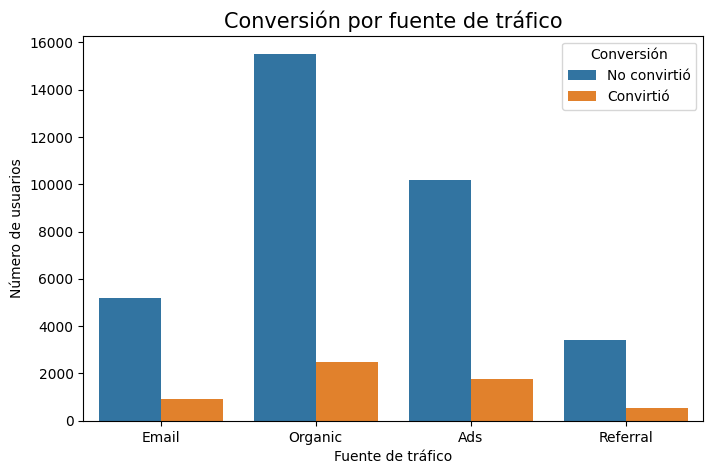

In [23]:
# Conteos de conversión por fuente de tráfico
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="traffic_source",
    hue="converted"
)

plt.title("Conversión por fuente de tráfico", fontsize=15)
plt.xlabel("Fuente de tráfico")
plt.ylabel("Número de usuarios")
plt.legend(title="Conversión", labels=["No convirtió", "Convirtió"])
plt.show()

 **Lectura del gráfico:**
El gráfico muestra diferencias importantes en el volumen de usuarios entre las fuentes de tráfico. Organic concentra la mayor cantidad de usuarios y, en consecuencia, también el mayor número absoluto de conversiones. Referral presenta el menor volumen total. Por ello, los conteos permiten comparar el tamaño de cada canal, pero no son suficientes para evaluar cuál convierte de manera más efectiva.

In [24]:
# Tabla normalizada por fuente de tráfico
tabla_trafico_norm = pd.crosstab(
    df["traffic_source"],
    df["converted"],
    normalize="index"
)

tabla_trafico_norm

converted,0,1
traffic_source,,
Ads,0.852618,0.147382
Email,0.850073,0.149927
Organic,0.862123,0.137877
Referral,0.861188,0.138812


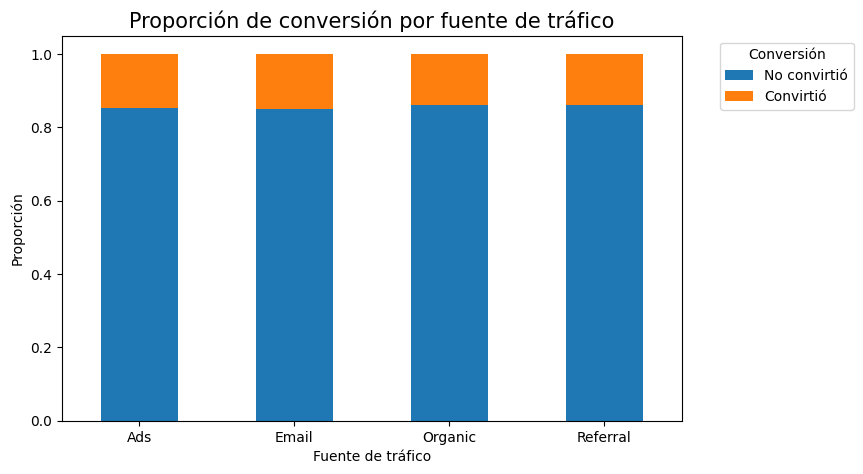

In [25]:
# Proporción de conversión por fuente de tráfico
tabla_trafico_norm.plot(
    kind="bar",
    stacked=True,
    figsize=(8, 5)
)

plt.title("Proporción de conversión por fuente de tráfico", fontsize=15)
plt.xlabel("Fuente de tráfico")
plt.ylabel("Proporción")
plt.legend(
    title="Conversión",
    labels=["No convirtió", "Convirtió"],
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)
plt.xticks(rotation=0)
plt.show()

 **Lectura del gráfico:** 
Al comparar proporciones, las diferencias entre canales son pequeñas. Email (14.99%) y Ads (14.74%) presentan las tasas de conversión más altas, mientras que Referral (13.88%) y Organic (13.79%) muestran valores ligeramente menores. Este patrón es consistente con la asociación estadísticamente significativa encontrada mediante la prueba chi-cuadrada, aunque la magnitud de las diferencias es reducida.

### Relación entre el tipo de usuario y la conversión

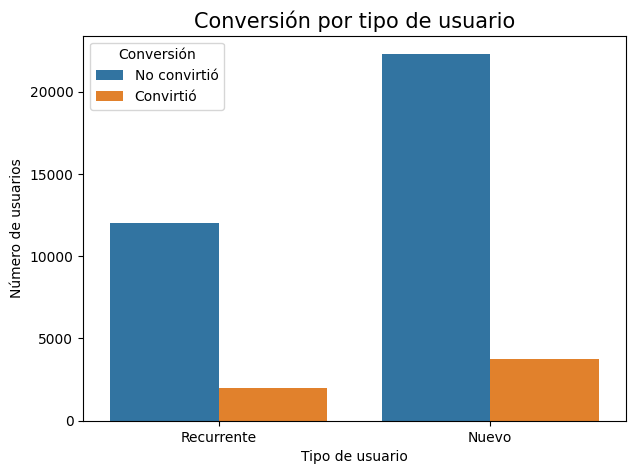

In [26]:
# Conteos de conversión por tipo de usuario
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="user_type",
    hue="converted"
)

plt.title("Conversión por tipo de usuario", fontsize=15)
plt.xlabel("Tipo de usuario")
plt.ylabel("Número de usuarios")
plt.legend(title="Conversión", labels=["No convirtió", "Convirtió"])
plt.show()

 **Lectura del gráfico:**

El gráfico muestra un mayor número absoluto de conversiones entre los usuarios nuevos. Sin embargo, este resultado está influido por el mayor tamaño de este grupo dentro del dataset, por lo que los conteos por sí solos no permiten concluir que los usuarios nuevos tengan una mayor probabilidad de convertir.

In [27]:
# Tabla normalizada por tipo de usuario
tabla_usuario_norm = pd.crosstab(
    df["user_type"],
    df["converted"],
    normalize="index"
)

tabla_usuario_norm

converted,0,1
user_type,,
Nuevo,0.856413,0.143587
Recurrente,0.859096,0.140904


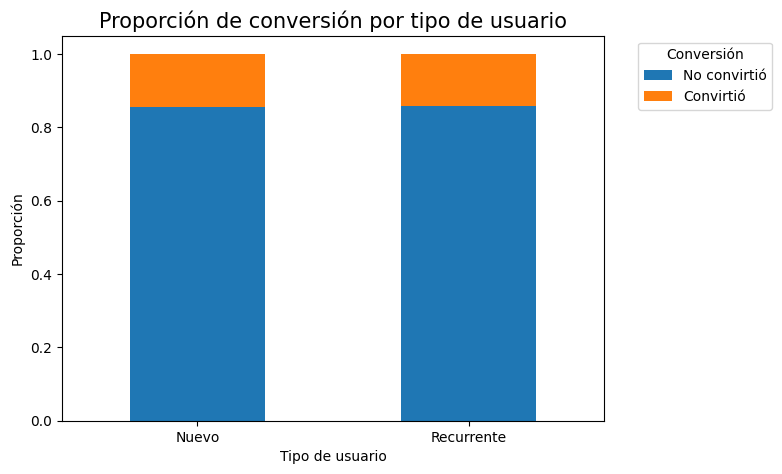

In [28]:
# Proporción de conversión por tipo de usuario
tabla_usuario_norm.plot(
    kind="bar",
    stacked=True,
    figsize=(7, 5)
)

plt.title("Proporción de conversión por tipo de usuario", fontsize=15)
plt.xlabel("Tipo de usuario")
plt.ylabel("Proporción")

plt.legend(
    title="Conversión",
    labels=["No convirtió", "Convirtió"],
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.xticks(rotation=0)
plt.show()

 **Lectura del gráfico:** 

Las proporciones de conversión son prácticamente iguales entre ambos grupos: 14.36% para usuarios nuevos y 14.09% para usuarios recurrentes. La diferencia de 0.27 puntos porcentuales es muy pequeña y coincide con el resultado de la prueba chi-cuadrada, que no encontró una asociación estadísticamente significativa entre el tipo de usuario y la conversión

## 7. Ingreso por usuario expuesto

El gasto medio entre compradores no cuenta toda la historia: una página puede tener compradores que gastan mucho, pero convertir a pocas personas. Por eso calculé también el ingreso total dividido entre **todos los usuarios expuestos**, incluidos quienes no compraron.

En este dataset, los usuarios que no convirtieron tienen gasto igual a cero. Para cuantificar la incertidumbre de la diferencia entre A y B, añadí una prueba t de Welch y un intervalo de confianza del 95 % sobre el gasto de todos los usuarios. Este análisis supone observaciones independientes y una asignación A/B adecuada.


In [29]:
# Ingreso por usuario expuesto: incluye a quienes no compraron.
if not (df.loc[df['converted'].eq(0), 'gasto'] == 0).all():
    raise ValueError('Hay gasto distinto de cero entre usuarios no convertidos.')

resumen_economico = df.groupby('landing').agg(
    usuarios=('user_id', 'nunique'),
    conversiones=('converted', 'sum'),
    ingreso_total=('gasto', 'sum'),
    ingreso_por_usuario=('gasto', 'mean')
)
resumen_economico['conversion_pct'] = 100 * resumen_economico['conversiones'] / resumen_economico['usuarios']
display(resumen_economico.round(2))

ingreso_A = df.loc[df['landing'] == 'A', 'gasto']
ingreso_B = df.loc[df['landing'] == 'B', 'gasto']
resultado = ttest_ind(ingreso_B, ingreso_A, equal_var=False)
diferencia = ingreso_B.mean() - ingreso_A.mean()
var_A, var_B = ingreso_A.var(ddof=1), ingreso_B.var(ddof=1)
n_A, n_B = len(ingreso_A), len(ingreso_B)
error = np.sqrt(var_A / n_A + var_B / n_B)
grados_libertad = (var_A / n_A + var_B / n_B)**2 / (
    (var_A / n_A)**2 / (n_A - 1) + (var_B / n_B)**2 / (n_B - 1)
)
intervalo = stats.t.interval(0.95, grados_libertad, loc=diferencia, scale=error)
print(f'Diferencia B - A: {diferencia:.2f} unidades por usuario')
print(f'IC 95 %: [{intervalo[0]:.2f}, {intervalo[1]:.2f}]')
print(f'Prueba t de Welch: p = {resultado.pvalue:.3g}')


,usuarios,conversiones,ingreso_total,ingreso_por_usuario,conversion_pct
landing,,,,,
A,19982,2512,153449.47,7.68,12.57
B,20018,3194,219572.68,10.97,15.96


Diferencia B - A: 3.29 unidades por usuario
IC 95 %: [2.79, 3.79]
Prueba t de Welch: p = 1.11e-37


## 8. Conclusiones y recomendaciones

El objetivo es decidir qué versión de la página conviene mantener, sin perder de vista que una diferencia estadística no siempre implica una mejora importante para el negocio.


### ¿Qué aprendí del experimento?

**La versión B tuvo mejores resultados.** Su tasa de conversión fue del **15.96 %**, frente al **12.57 %** de A: una diferencia de 3.39 puntos porcentuales. Entre quienes compraron, el gasto medio fue de 68.75 en B y 61.09 en A. Las dos comparaciones dieron valores *p* inferiores a 0.001.

**La mejora también aparece al incluir a todos los usuarios.** El ingreso por usuario expuesto fue de **7.68** en A y **10.97** en B. Esto representa **3.29 unidades más por usuario**, un aumento relativo del **42.8 %**. El intervalo de confianza del 95 % para la diferencia va de **2.79 a 3.79** unidades; la prueba t de Welch también dio *p* < 0.001.

**Los canales de tráfico merecen atención, pero no una decisión precipitada.** Email y Ads tuvieron tasas de conversión ligeramente mayores que Referral y Organic. La prueba chi-cuadrada encontró una asociación con la conversión (*p* = 0.034), aunque la diferencia entre canales fue pequeña. No redistribuiría presupuesto sin conocer también los costos de adquisición.

**Ser usuario nuevo o recurrente no marcó una diferencia clara.** En este experimento las tasas de conversión fueron similares y la prueba chi-cuadrada no encontró una asociación significativa (*p* = 0.474).

### Qué haría después

1. **Probaría un despliegue controlado de B**, tras verificar la asignación aleatoria, el seguimiento de conversiones y posibles métricas de protección.
2. **Revisaría los costos y el valor generado por canal** antes de cambiar la inversión en marketing.
3. **Monitorearía el resultado después del cambio**, para comprobar que la mejora se mantiene.

**Límite del análisis:** no hay información sobre costos, rentabilidad, asignación aleatoria ni comportamiento a largo plazo. Las diferencias entre canales son asociaciones observadas, no pruebas de que un canal cause más conversiones.
